# Review Sentiment for a Small-Business App

An app for small businesses gets thousands of reviews in the App Store, Google Play and on Trustpilot. Star averages say how happy customers are, but not why, and not which releases made them unhappy. This notebook reads the reviews themselves:

1. clean the reviews and use the stars as labels,
2. train a model that tells positive from negative by the text, and test it honestly,
3. sort the complaints into themes and follow them over ten years,
4. find good-star reviews that still complain,
5. connect reviews to app releases.

**Data:** synthetic, generated by [make_data.py](make_data.py): [reviews.csv](reviews.csv), 9,777 reviews from October 2016 to November 2026, and [releases.csv](releases.csv), the app releases with their dates and contents.

In [1]:
import re
import textwrap
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgb
import plotly.graph_objects as go
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score, classification_report, confusion_matrix

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
reviews = pd.read_csv("reviews.csv", parse_dates=["posted_at"])
reviews["text"] = (reviews["title"].fillna("") + " " + reviews["review_text"].fillna("")).str.strip()

print(len(reviews), "reviews from", reviews["posted_at"].min().date(), "to", reviews["posted_at"].max().date())
reviews.groupby("store").size()

9777 reviews from 2016-10-01 to 2026-11-03


store
App Store      5060
Google Play    4251
Trustpilot      466
dtype: int64

## 1. Cleaning

When a customer edits a review, often changing the stars, it is collected again. Reviews with the same store, author and text are treated as one, and only the latest version is kept. Authors with no real name, such as "A Google user", are never treated as repeats, because different people share that name.

Trustpilot reviews arrived in one batch when their collection started in November 2025. Their dates are import dates, not when they were written, so they are left out of the trends over time.

In [3]:
generic_authors = {"a google user", "anonymous", ""}
key = (reviews["store"] + "|" + reviews["author"].fillna("").str.strip().str.lower() + "|"
       + reviews["review_text"].fillna("").str.strip().str.lower())
known_author = ~reviews["author"].fillna("").str.strip().str.lower().isin(generic_authors)
repeat = known_author & key.duplicated(keep="last")

repeats = reviews[known_author & key.duplicated(keep=False)]
print("Reviews posted more than once by the same author with the same text:", repeats.groupby(key[repeats.index]).ngroups)
print("Of those, the stars changed between posts:", (repeats.groupby(key[repeats.index])["rating"].nunique() > 1).sum())
print("Older copies removed:", repeat.sum())

reviews = reviews[~repeat].copy()
print("Reviews kept:", len(reviews))

reviews["trustpilot_batch"] = (reviews["store"] == "Trustpilot") & (reviews["posted_at"] < "2025-12-01")
print("Trustpilot reviews imported in the first batch (November 2025):", reviews["trustpilot_batch"].sum(),
      "of", (reviews["store"] == "Trustpilot").sum())

reviews["rating"].value_counts().sort_index()

Reviews posted more than once by the same author with the same text: 134
Of those, the stars changed between posts: 93
Older copies removed: 134
Reviews kept: 9643
Trustpilot reviews imported in the first batch (November 2025): 319 of 459


rating
1    1859
2     649
3     510
4    1740
5    4885
Name: count, dtype: int64

## 2. A sentiment model

The stars are the answer key: 4 and 5 stars are positive (1), 1 and 2 stars are negative (0), and 3-star reviews are mixed, so they are left out. Guessing "positive" every time is the benchmark to beat.

The model reads single words and pairs of words such as "not good", weighs them by TF-IDF and draws a dividing line with a linear SVM. It is tested two ways: on reviews from all years mixed (5-fold cross-validation), and the fairer way for how it would be used, trained on reviews before 2024 and tested on 2024 onward. **Complaints caught** is the share of negative reviews it spots, **praise caught** the same for positive ones, and **balanced accuracy** their average, so the many positive reviews can't hide weak results on complaints.

In [4]:
labeled = reviews[reviews["rating"] != 3].copy()
labeled["label"] = (labeled["rating"] >= 4).astype(int)

texts = labeled["text"].tolist()
labels = labeled["label"].tolist()

print(labeled["label"].value_counts().rename({1: "positive", 0: "negative"}))
print("Baseline accuracy (always guess positive):", round(labeled["label"].mean(), 3))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def sentiment_model():
    return Pipeline([("vectorizer", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
                     ("classifier", LinearSVC(random_state=42))])

def scores(y_true, y_pred):
    return pd.Series({
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "complaints caught": recall_score(y_true, y_pred, pos_label=0),
        "praise caught": recall_score(y_true, y_pred, pos_label=1),
    }).round(3)

labeled["predicted"] = cross_val_predict(sentiment_model(), texts, labels, cv=cv)
all_years = scores(labeled["label"], labeled["predicted"])

past, recent = labeled[labeled["posted_at"] < "2024-01-01"], labeled[labeled["posted_at"] >= "2024-01-01"]
time_model = sentiment_model().fit(past["text"], past["label"])
recent_test = scores(recent["label"], time_model.predict(recent["text"]))

pd.DataFrame({"all years, mixed test": all_years, "trained before 2024, tested on 2024+": recent_test})

label
positive    6625
negative    2508
Name: count, dtype: int64
Baseline accuracy (always guess positive): 0.725


,"all years, mixed test","trained before 2024, tested on 2024+"
accuracy,0.961,0.953
balanced accuracy,0.941,0.939
complaints caught,0.895,0.892
praise caught,0.986,0.986


In [5]:
print(classification_report(labeled["label"], labeled["predicted"], target_names=["negative", "positive"], digits=3))
pd.DataFrame(confusion_matrix(labeled["label"], labeled["predicted"]),
             index=["truly negative", "truly positive"], columns=["predicted negative", "predicted positive"])

              precision    recall  f1-score   support

    negative      0.960     0.895     0.927      2508
    positive      0.961     0.986     0.973      6625

    accuracy                          0.961      9133
   macro avg      0.961     0.941     0.950      9133
weighted avg      0.961     0.961     0.961      9133



,predicted negative,predicted positive
truly negative,2245,263
truly positive,93,6532


By year: older years are mostly positive and easier, so the overall score is higher than what to expect on new reviews.

In [6]:
labeled["year"] = labeled["posted_at"].dt.year
labeled.groupby("year").apply(lambda d: pd.Series({
    "reviews": len(d),
    "share positive": round(d["label"].mean(), 2),
    "accuracy": round((d["predicted"] == d["label"]).mean(), 3),
    "balanced accuracy": round(balanced_accuracy_score(d["label"], d["predicted"]), 3),
}))

,reviews,share positive,accuracy,balanced accuracy
year,,,,
2016,323.0,0.91,1.000,1.000
2017,1225.0,0.90,0.982,0.955
2018,1118.0,0.85,0.963,0.915
2019,1031.0,0.57,0.952,0.948
2020,893.0,0.74,0.962,0.942
2021,851.0,0.75,0.959,0.941
2022,759.0,0.65,0.960,0.948
2023,731.0,0.64,0.941,0.923
2024,649.0,0.56,0.951,0.945


### How the model works

The main model is a **binary classifier**: it sorts each review into one of two classes, negative or positive.

**1. Labels from the stars**

Each review $i$ with $s_i$ stars gets a label:

$$
y_i = \begin{cases} +1 & \text{if } s_i \ge 4 \text{ (positive)} \\ -1 & \text{if } s_i \le 2 \text{ (negative)} \end{cases}
$$

3-star reviews get no label and are left out of training. (In the notebook the labels are written as `1` and `0`; scikit-learn turns them into $+1$ and $-1$ internally)

**2. Text to numbers (Tf*Idf)**

A "document" is one review (its title and text together), and a "term" is a single word or a pair of words (for example "not good"). Only terms found in at least 2 reviews are kept, which gives a vocabulary of 2,419 words and word pairs.

*Term Frequency (TF)* measures how many times a term appears in one review:

$$
\text{TF}(t, d) = \text{number of times term } t \text{ appears in review } d
$$

Each review's final vector is scaled to length 1 at the end (see below), which stops long reviews from dominating in the same way.

*Inverse Document Frequency (IDF)* measures how rare or common a term is across all the reviews. Terms like "app" appear in most reviews and say little about sentiment, so they get a low IDF. Rare, telling terms like "garbage" get a high one:

$$
\text{IDF}(t) = \ln\left(\frac{1 + N}{1 + \text{df}(t)}\right) + 1
$$

+ $N$ is the number of reviews the model learns from: 9,133 (all 1, 2, 4 and 5 star reviews, after removing repeats).
+ $\text{df}(t)$ is the number of reviews that contain term $t$ at least once.
+ The $+1$ inside the fraction avoids dividing by zero, and the $+1$ at the end keeps terms found in every review from being dropped entirely.

Examples from the reviews:

| Term | Reviews containing it, $\text{df}(t)$ | $\text{IDF}(t)$ |
|---|---|---|
| app | 2,625 | 2.25 |
| great | 1,042 | 3.17 |
| price | 222 | 4.71 |
| greedy | 107 | 5.44 |
| garbage | 73 | 5.82 |
| not good | 74 | 5.80 |

Each term's weight in a review is the product of the two:

$$
w_{t,d} = \text{TF}(t, d) \cdot \text{IDF}(t)
$$

For example, in the review "Garbage app. Total garbage.", the term "garbage" appears twice, so its weight is $2 \times 5.82 = 11.64$, while "app" gets $1 \times 2.25 = 2.25$.

Each review becomes a vector $\mathbf{x}_d$ of these weights, scaled to length 1 so long reviews don't dominate:

$$
\mathbf{x}_d \leftarrow \frac{\mathbf{x}_d}{\lVert \mathbf{x}_d \rVert_2},
\qquad
\lVert \mathbf{x}_d \rVert_2 = \sqrt{\sum_t w_{t,d}^2}
$$

During testing, each test round learns its IDF from that round's training reviews only, so the values there differ very slightly from the table above.

**3. Learning the dividing line (linear SVM)**

The model learns one weight $\theta_t$ per term, stored as a vector $\boldsymbol{\theta}$, plus a constant $b$, by minimizing:

$$
\min_{\boldsymbol{\theta},\, b}\; \frac{1}{2}\lVert \boldsymbol{\theta} \rVert^2 \;+\; C \sum_{i} \max\!\big(0,\; 1 - y_i(\boldsymbol{\theta} \cdot \mathbf{x}_i + b)\big)^2
$$

+ **The first part** keeps the weights small, so the model doesn't rely too much on any single word.
+ **The second part** penalizes reviews that land on the wrong side of the line or too close to it, within 1. A review that is clearly on the right side costs nothing.
+ **$C = 1$** (the default) balances the two parts.

(scikit-learn's `LinearSVC` also includes $b$ in the size penalty, a small technical difference from this textbook form.)

**4. The text score and the decision**

For any review $\mathbf{x}$, the text score is:

$$
f(\mathbf{x}) = \boldsymbol{\theta} \cdot \mathbf{x} + b = \sum_t \theta_t\, x_t + b
$$

Each term adds its weight times how much the review uses it: positive words push the score up and negative ones push it down. The decision is:

$$
\hat{y} = \begin{cases} \text{positive} & \text{if } f(\mathbf{x}) > 0 \\ \text{negative} & \text{if } f(\mathbf{x}) \le 0 \end{cases}
$$

The text score in the 3D chart at the end is $f(\mathbf{x})$. It's proportional to the distance from the dividing line, since the exact distance is $f(\mathbf{x}) / \lVert \boldsymbol{\theta} \rVert$. The training pushes reviews to land beyond $\pm 1$, so a score past $+1$ or $-1$ means the text clearly leans one way, and a score between them is a close call. It isn't a probability: $+1.12$ means "clearly positive", not "112% positive".

**5. The scores in the notebook**

With negative reviews counted as the class to catch:

$$
\text{accuracy} = \frac{\text{correct calls}}{\text{all reviews}}
\qquad
\text{complaints caught} = \frac{\text{negatives called negative}}{\text{all negatives}}
\qquad
\text{praise caught} = \frac{\text{positives called positive}}{\text{all positives}}
$$

$$
\text{balanced accuracy} = \frac{\text{complaints caught} + \text{praise caught}}{2}
$$

Balanced accuracy weights both classes equally, so the many positive reviews can't hide weak results on complaints.

### Words that push a review positive or negative

The model trained on all reviews, checked on three made-up ones (`1` positive, `0` negative), and the words and word pairs that pull a review most toward each side.

In [7]:
clf_pipeline = sentiment_model().fit(texts, labels)

print(clf_pipeline.predict(["Easy to use, my clients love the professional invoices. Saves me hours every week.",
                           "The app keeps crashing and support never answers. Lost an estimate twice.",
                           "Too expensive after the last price increase."]))

vec = clf_pipeline.named_steps["vectorizer"]
svm = clf_pipeline.named_steps["classifier"]
weights = pd.Series(svm.coef_[0], index=vec.get_feature_names_out()).sort_values()

pd.DataFrame({"most negative": weights.head(25).index, "most positive": weights.tail(25).index[::-1]})

[1 0 0]

,most negative,most positive
0,terrible,good app
1,frustrating,app but
2,avoid,but
3,disappointed,good
4,getting worse,favorite
5,worse,still my
6,used,my favorite
7,very bad,not bad
8,bad,app
9,not download,works


A word's weight doesn't say what it means in context, so it helps to read the reviews that contain it. Change `WORD` to check another one.

In [8]:
WORD = "crashing"   # any word or word pair from the driver list

hits = labeled[labeled["text"].str.lower().str.contains(rf"\b{re.escape(WORD)}\b", regex=True)]
print(f"'{WORD}': {len(hits)} reviews, {hits['label'].mean():.0%} positive")
hits.sort_values("posted_at", ascending=False)[["posted_at", "store", "rating", "text"]].head(10)

'crashing': 35 reviews, 20% positive


,posted_at,store,rating,text
9566,2026-07-17 23:13:07,App Store,1,Review The app keeps crashing when I open an estimate. The PDF my customer gets looks different from the app.
9338,2026-04-05 01:17:07,App Store,1,"Frustrating Bait and switch: free to start, then they make u pay. The app keeps crashing when I open an estimate."
9072,2025-12-03 14:31:26,Trustpilot,5,"Best invoicing app Works well, but I cancelled my subscription and still got charged. The app keeps crashing when I open an estimate"
8566,2025-09-03 12:23:06,App Store,1,Not worth it I have used it for years for my roofing business. The app keeps crashing when I open an estimate.
8477,2025-07-16 21:25:06,Google Play,1,This used to be the best app for estimates. I do painting work. Not good at all. Greedy. Not worth the money anymore. The app keeps crashing when I open an estimate.
8238,2025-03-01 16:39:34,App Store,1,this used to be the best app for estimates. the app keeps crashing when i open an estimate. it keeps logging me out
7151,2023-08-24 06:04:45,App Store,1,Not worth it I have used it for years for my flooring business. The app keeps crashing when I open an estimate. The update changed everything and now it's hard to find anything.
6404,2022-09-07 03:56:16,Google Play,1,Too expensive. The monthly price doubled this year. The app keeps crashing when I open an estimate
6001,2022-03-22 11:34:06,Google Play,1,Terrible. The app keeps crashing when I open an estimate.
5744,2021-12-03 06:21:54,Google Play,1,Garbage app. Can't send an invoice without upgrading to premium. The app keeps crashing when I open an estimate


Words that pull most toward negative in older reviews and in recent ones. Words only in the recent column are newer complaints.

In [9]:
# top negative driver words: older reviews vs recent ones
def top_negative(df, n=20):
    m = sentiment_model().fit(df["text"], df["label"])
    w = pd.Series(m.named_steps["classifier"].coef_[0], index=m.named_steps["vectorizer"].get_feature_names_out())
    return w.sort_values().head(n).index.tolist()

pd.DataFrame({"2016 to 2023": top_negative(labeled[labeled["posted_at"] < "2024-01-01"]),
              "2024 onward": top_negative(labeled[labeled["posted_at"] >= "2024-01-01"])})

,2016 to 2023,2024 onward
0,terrible,avoid
1,frustrating,terrible
2,disappointed,disappointed
3,getting worse,used
4,worse,worse
5,uninstalling,getting worse
6,ok it,penny keeps
7,do not,meh
8,download,bad
9,not download,to love


### Reviews where the text and the stars disagree

Each review is judged by a version of the model that never saw it. Some of these are customers who picked the wrong stars, some are mixed reviews, and some are the model's mistakes.

In [10]:
mismatch = labeled[labeled["predicted"] != labeled["label"]]
print(len(mismatch), "of", len(labeled), "reviews read differently from their stars")
mismatch.sort_values("posted_at", ascending=False)[["posted_at", "store", "rating", "text"]].head(15)

356 of 9133 reviews read differently from their stars


,posted_at,store,rating,text
9767,2026-10-27 03:24:12,Google Play,5,way too expensive for a small business. Useless on a job site with no internet connection.
9750,2026-10-21 16:18:09,Trustpilot,1,Terrible My customers love the professional invoices. Great app. Getting paid is so much faster now
9739,2026-10-15 13:40:32,App Store,5,Update Greedy. Not worth the money anymore
9712,2026-10-01 17:13:51,App Store,1,looks professional and my clients notice. getting paid is so much faster now.
9645,2026-08-30 17:22:19,App Store,1,Update It stopped working after the update.
9642,2026-08-28 08:26:18,Trustpilot,5,Update It used to be free and now they want a monthly subscription
9612,2026-08-13 06:38:00,Google Play,4,Does the job.
9607,2026-08-10 00:22:20,Google Play,5,basic features are now behind a paywall
9590,2026-08-02 00:02:17,App Store,1,I can send an estimate from the job site in a few minutes. Easy to use
9574,2026-07-22 04:56:15,App Store,4,my customer paid by credit card and the funds are on hold.


## 3. Why customers are unhappy

Every 1 or 2 star review is sorted into themes with lists of words that signal each one (for example "crash", "glitch" and "bug" for crashes and bugs). The lists are in the cell, so they are easy to check or change. A review can be in several themes, so the shares add up to more than 100%, and "no theme" shows how many complaints the lists miss.

In [11]:
THEMES = {
    "pricing and subscription": r"\b(price\w*|expensive|subscri\w*|monthly|per month|a month|fees?|costs?|charg\w*|refund\w*|cancel\w*|premium|upgrad\w*|paywall|used to be free|was free|free version|no longer free|money|greed\w*|rip ?off|scam|increase\w*)\b",
    "crashes and bugs": r"\b(crash\w*|bugs?|buggy|glitch\w*|freez\w*|errors?|broken|not working|doesn'?t work|won'?t (?:open|load|work)|stopped working|keeps (?:closing|crashing)|force clos\w*)\b",
    "speed and connection": r"\b(slow\w*|lag\w*|loading|takes forever|sync\w*|spinning|offline|internet|connection|server\w*)\b",
    "payments": r"\b(payments?|paypal|stripe|credit cards?|deposits?|get paid|getting paid|tap to pay|payouts?|funds|bank|checkout|processing fees?)\b",
    "support": r"\b(support|customer service|respon\w*|repl(?:y|ied|ies)|contact\w*|no one|nobody|tickets?|chat)\b",
    "login and account": r"\b(log ?in|logged out|sign ?in|signed out|password|locked|verif\w*|two.factor|2fa)\b",
    "lost data": r"\b(lost|lose|losing|deleted|disappear\w*|missing|wiped|erased)\b",
    "sending and printing": r"\b(print\w*|pdf|send\w*|sent|deliver\w*|e-?mail\w*|text messages?|sms)\b",
    "features and changes": r"\b(features?|options?|wish|would be nice|need to add|can'?t (?:add|change|edit)|confus\w*|complicated|difficult|hard to|update\w*|new version|changed|layout|design|navigation|ads|pop ?ups?)\b",
}

negative = reviews[reviews["rating"] <= 2].copy()
lower = negative["text"].str.lower()
for theme, pattern in THEMES.items():
    negative[theme] = lower.str.contains(pattern, regex=True)
negative["no theme"] = ~negative[list(THEMES)].any(axis=1)

print(len(negative), "negative reviews (1 or 2 stars)")
(negative[list(THEMES) + ["no theme"]].mean().sort_values(ascending=False) * 100).round(1).rename("% of negative reviews")

2508 negative reviews (1 or 2 stars)


pricing and subscription    39.7
features and changes        27.6
no theme                    18.9
payments                    17.5
sending and printing        16.6
crashes and bugs            10.7
support                     10.5
speed and connection         7.1
lost data                    3.3
login and account            1.9
Name: % of negative reviews, dtype: float64

Two recent examples for each of the five largest themes, as a check that the word lists pick up the right complaints:

In [12]:
for theme in list(THEMES)[:5]:
    example = negative[negative[theme]].sort_values("posted_at", ascending=False).head(2)
    for _, row in example.iterrows():
        print(f"[{theme}] {row['posted_at'].date()} {row['store']}: {row['text'][:180]}")
    print()

[pricing and subscription] 2026-10-27 Trustpilot: It was great until the last update. Greedy. Not worth the money anymore.
[pricing and subscription] 2026-10-23 App Store: they charge a fee on every payment on top of the subscription. i wish i could set my own tax rates.

[crashes and bugs] 2026-11-03 Google Play: It stopped working after the update. The new layout is confusing.
[crashes and bugs] 2026-09-30 App Store: Invoicing app It was great until the last update. Locked out of my account and the password reset doesn't work.

[speed and connection] 2026-09-20 Trustpilot: Meh. Downloaded it last month. Freezes on the loading screen.
[speed and connection] 2026-06-26 App Store: Invoicing app Not good at all. Very slow to load.

[payments] 2026-10-23 App Store: they charge a fee on every payment on top of the subscription. i wish i could set my own tax rates.
[payments] 2026-10-21 Trustpilot: Terrible My customers love the professional invoices. Great app. Getting paid is so much fast

### How complaints changed

The share of each year's negative reviews that mention each theme, biggest themes on top (the Trustpilot batch is left out). Years with fewer than 30 negative reviews are in italics, because their shares are unreliable.

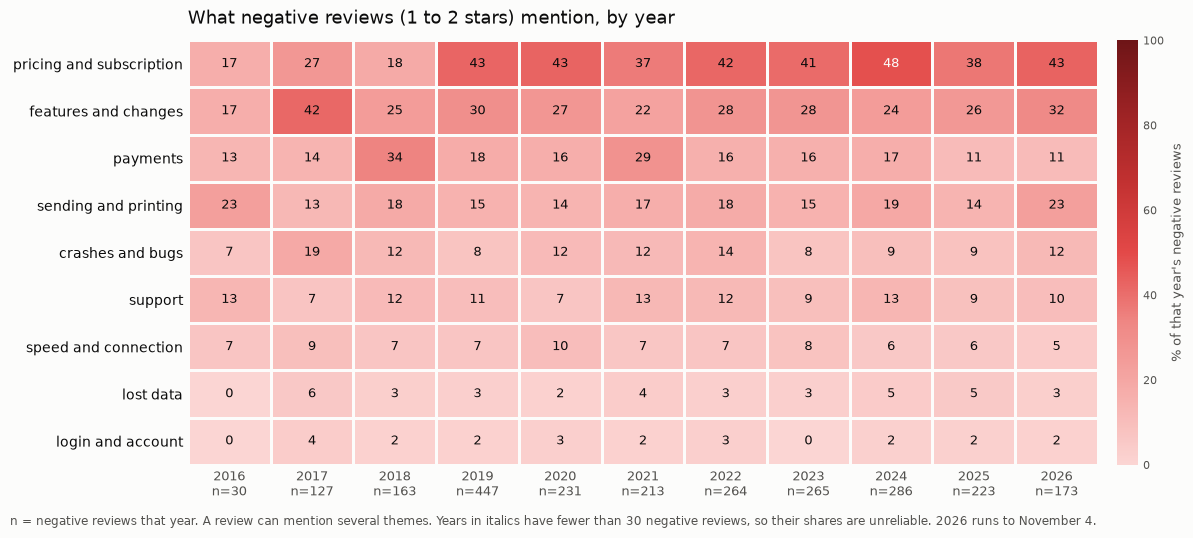

In [13]:
trend = negative[~negative["trustpilot_batch"]].copy()
trend["year"] = trend["posted_at"].dt.year
by_year = (trend.groupby("year")[list(THEMES)].mean() * 100).round(0).astype(int)
by_year.insert(0, "negative reviews", trend.groupby("year").size())

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgb

# share of negative reviews mentioning each theme, by year (Trustpilot batch excluded)
hm = trend.copy()
hm["year"] = hm["posted_at"].dt.year
share = hm.groupby("year")[list(THEMES)].mean().mul(100).T
share = share.loc[share.mean(axis=1).sort_values(ascending=False).index]   # biggest themes on top
counts = hm.groupby("year").size()

reds = ["#fbd5d3", "#f6aeab", "#ef8784", "#e34948", "#c23131", "#9c2224", "#6e1517"]
cmap = LinearSegmentedColormap.from_list("reds", reds)
surface, ink, ink_muted = "#fcfcfb", "#0b0b0b", "#52514e"

fig, ax = plt.subplots(figsize=(12, 5.2), facecolor=surface)
ax.set_facecolor(surface)
mesh = ax.pcolormesh(share.values, cmap=cmap, vmin=0, vmax=100, edgecolors=surface, linewidth=2)

for i, theme in enumerate(share.index):
    for j, year in enumerate(share.columns):
        v = share.iloc[i, j]
        r, g, b = to_rgb(cmap(v / 100))
        dark_cell = 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.45
        ax.text(j + 0.5, i + 0.5, f"{v:.0f}", ha="center", va="center", fontsize=9,
                color=surface if dark_cell else ink)

ax.set_xticks([j + 0.5 for j in range(len(share.columns))])
ax.set_xticklabels([f"{y}\nn={counts[y]}" for y in share.columns], fontsize=9, color=ink_muted)
for label, y in zip(ax.get_xticklabels(), share.columns):
    if counts[y] < 30:
        label.set_fontstyle("italic")
ax.set_yticks([i + 0.5 for i in range(len(share.index))])
ax.set_yticklabels(share.index, fontsize=10, color=ink)
ax.invert_yaxis()
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)

cbar = fig.colorbar(mesh, ax=ax, fraction=0.025, pad=0.02)
cbar.set_label("% of that year's negative reviews", color=ink_muted, fontsize=9)
cbar.outline.set_visible(False)
cbar.ax.tick_params(colors=ink_muted, labelsize=8, length=0)

ax.set_title("What negative reviews (1 to 2 stars) mention, by year", loc="left", fontsize=13, color=ink, pad=12)
fig.text(0.01, -0.02, "n = negative reviews that year. A review can mention several themes. "
         "Years in italics have fewer than 30 negative reviews, so their shares are unreliable. 2026 runs to November 4.",
         fontsize=8.5, color=ink_muted)
plt.tight_layout()
plt.show()

From 2024 on, by quarter. Check the count in the first column: quarters with few negative reviews give unreliable shares.

In [14]:
recent_neg = trend[trend["posted_at"] >= "2024-01-01"].copy()
recent_neg["quarter"] = recent_neg["posted_at"].dt.to_period("Q")
by_q = (recent_neg.groupby("quarter")[list(THEMES)].mean() * 100).round(0).astype(int)
by_q.insert(0, "negative reviews", recent_neg.groupby("quarter").size())
by_q

,negative reviews,pricing and subscription,crashes and bugs,speed and connection,payments,support,login and account,lost data,sending and printing,features and changes
quarter,,,,,,,,,,
2024Q1,66,52,9,8,20,8,3,6,26,26
2024Q2,87,44,7,7,21,9,1,5,18,17
2024Q3,72,47,15,4,12,17,3,3,17,28
2024Q4,61,52,7,3,13,21,2,5,16,30
2025Q1,63,33,10,10,16,8,2,6,17,21
2025Q2,46,35,2,2,9,15,0,9,22,35
2025Q3,55,36,11,7,7,7,2,4,9,27
2025Q4,59,46,10,3,12,7,5,3,10,24
2026Q1,51,43,8,4,6,14,2,2,27,33


## 4. Hidden complaints

Reviews with 4 or 5 stars whose text reads negative, judged by a version of the model that never saw them. These customers gave good ratings but still complained, so star averages miss them. Read them before quoting: some are model mistakes.

In [15]:
# text score for each review, from a model that never saw it (below 0 = reads negative)
labeled["text_score"] = cross_val_predict(sentiment_model(), texts, labels, cv=cv, method="decision_function")

hidden = labeled[(labeled["rating"] >= 4) & (labeled["text_score"] < 0)].copy()
lower = hidden["text"].str.lower()
for theme, pattern in THEMES.items():
    hidden[theme] = lower.str.contains(pattern, regex=True)

print(len(hidden), "hidden complaints (4 or 5 stars, text reads negative)")
print((hidden[list(THEMES)].mean() * 100).round(0).astype(int).sort_values(ascending=False).rename("% mentioning"))

# most negative first, recent ones only
hidden[hidden["posted_at"] >= "2025-01-01"].sort_values("text_score")[
    ["posted_at", "store", "rating", "text_score", "text"]].head(20)

93 hidden complaints (4 or 5 stars, text reads negative)
pricing and subscription    34
features and changes        30
payments                    23
sending and printing        15
support                     10
speed and connection         9
crashes and bugs             6
lost data                    5
login and account            2
Name: % mentioning, dtype: int64


,posted_at,store,rating,text_score,text
8532,2025-08-09 17:31:13,App Store,4,-0.910318,Easy to use the monthly price doubled this year. Freezes on the loading screen.
8522,2025-08-04 20:30:36,Google Play,5,-0.907039,the monthly price doubled this year.
8765,2025-11-10 12:01:10,Trustpilot,4,-0.782548,a deposit never showed up in my bank account. Too many pop ups asking me to upgrade
9739,2026-10-15 13:40:32,App Store,5,-0.762502,Update Greedy. Not worth the money anymore
9767,2026-10-27 03:24:12,Google Play,5,-0.761967,way too expensive for a small business. Useless on a job site with no internet connection.
8178,2025-02-02 02:52:12,Google Play,5,-0.761864,i cancelled my subscription and still got charged.
8266,2025-03-16 09:02:46,Google Play,5,-0.714658,can't send an invoice without upgrading to premium.
9607,2026-08-10 00:22:20,Google Play,5,-0.703492,basic features are now behind a paywall
8460,2025-07-07 13:36:36,App Store,5,-0.691593,Basic features are now behind a paywall.
9642,2026-08-28 08:26:18,Trustpilot,5,-0.674108,Update It used to be free and now they want a monthly subscription


Sentiment by quarter and store from 2024 on: the share of reviews that are positive (`mean`) and how many reviews it is based on (`size`), without 3-star reviews and the Trustpilot batch.

In [16]:
t = labeled[~labeled["trustpilot_batch"]].copy()
t["quarter"] = t["posted_at"].dt.to_period("Q")
by_store = t[t["posted_at"] >= "2024-01-01"].pivot_table(index="quarter", columns="store", values="label", aggfunc=["mean", "size"])
by_store["mean"] = by_store["mean"].round(2)
by_store

mean                             size                       
store   App Store Google Play Trustpilot App Store Google Play Trustpilot
quarter                                                                  
2024Q1       0.59        0.58        NaN     100.0        60.0        NaN
2024Q2       0.46        0.57        NaN     102.0        74.0        NaN
2024Q3       0.51        0.44        NaN      80.0        59.0        NaN
2024Q4       0.65        0.65        NaN      95.0        79.0        NaN
2025Q1       0.59        0.62        NaN      79.0        81.0        NaN
2025Q2       0.75        0.61        NaN      73.0        72.0        NaN
2025Q3       0.63        0.68        NaN      84.0        76.0        NaN
2025Q4       0.60        0.78       0.71     100.0        76.0        7.0
2026Q1       0.79        0.67       0.68      72.0        70.0       40.0
2026Q2       0.69        0.71       0.70      85.0        83.0       37.0
2026Q3       0.70        0.71       0.72      70.0        59.0       29.0
2026Q4       0.74        0.77       0.76      19.0        22.0       21.0

## 5. Reviews by app release

Each store review carries the app version the customer had, and the releases file has when each version came out and what it contained. App Store reviews are matched to App Store releases and Google Play reviews to Google Play releases.

In [17]:
def norm_version(v):
    if pd.isna(v):
        return None
    m = re.search(r"(\d+)\.(\d+)(?:\.(\d+))?", str(v))
    return f"{m.group(1)}.{m.group(2)}.{m.group(3) or 0}" if m else None

release_info = pd.read_csv("releases.csv", parse_dates=["released_at"])
release_info["version"] = release_info["version"].map(norm_version)

reviews["version"] = reviews["app_version"].map(norm_version)
app_reviews = reviews[reviews["store"].isin(["App Store", "Google Play"])]
with_version = app_reviews.dropna(subset=["version"])
matched = with_version.merge(release_info[["store", "version"]], on=["store", "version"], how="inner")
print("App reviews with a version:", len(with_version), "of", len(app_reviews))
print("Of those, matched to a known release:", len(matched), f"({len(matched) / len(with_version):.0%})")

App reviews with a version: 7727 of 9184
Of those, matched to a known release: 6897 (89%)


Versions with at least 20 reviews, least liked first. A version's reviews also reflect things outside the app, such as price changes made while it was current.

In [18]:
per_version = (with_version.assign(negative=lambda d: d["rating"] <= 2)
               .groupby(["store", "version"])
               .agg(reviews=("rating", "size"), share_negative=("negative", "mean"), avg_stars=("rating", "mean"),
                    first_review=("posted_at", "min"))
               .reset_index()
               .merge(release_info, on=["store", "version"], how="left"))
per_version["share_negative"] = per_version["share_negative"].round(2)
per_version["avg_stars"] = per_version["avg_stars"].round(2)

worst = per_version[per_version["reviews"] >= 20].sort_values("share_negative", ascending=False)
worst[["store", "version", "released_at", "reviews", "share_negative", "avg_stars", "is_hotfix", "tickets"]].head(15)

,store,version,released_at,reviews,share_negative,avg_stars,is_hotfix,tickets
124,App Store,3.89.0,NaT,28,0.68,2.39,NaN,NaN
208,Google Play,2.34.0,NaT,24,0.67,2.38,NaN,NaN
209,Google Play,2.34.1,2019-05-10,33,0.64,2.52,yes,3.0
210,Google Play,2.35.0,NaT,28,0.61,2.21,NaN,NaN
126,App Store,3.90.0,NaT,20,0.60,2.65,NaN,NaN
120,App Store,3.85.0,2024-02-18,27,0.56,2.74,no,15.0
54,App Store,3.34.0,2019-06-30,36,0.56,2.69,no,14.0
121,App Store,3.86.0,2024-03-19,22,0.55,2.59,no,14.0
112,App Store,3.79.0,2023-07-29,28,0.54,2.79,no,22.0
52,App Store,3.32.0,2019-05-08,38,0.53,2.92,no,11.0


The same for releases from 2024 on, with a lower bar of 10 reviews, since recent versions have fewer reviews:

In [19]:
recent_versions = per_version[(per_version["released_at"] >= "2024-01-01") & (per_version["reviews"] >= 10)]
recent_versions.sort_values("share_negative", ascending=False)[
    ["store", "version", "released_at", "reviews", "share_negative", "avg_stars", "is_hotfix", "tickets"]].head(10)

,store,version,released_at,reviews,share_negative,avg_stars,is_hotfix,tickets
288,Google Play,2.96.0,2024-01-10,10,0.60,2.70,no,11.0
151,Google Play,2.109.0,2025-02-21,19,0.58,2.79,no,16.0
120,App Store,3.85.0,2024-02-18,27,0.56,2.74,no,15.0
121,App Store,3.86.0,2024-03-19,22,0.55,2.59,no,14.0
142,Google Play,2.102.0,2024-05-26,17,0.53,2.65,no,11.0
143,Google Play,2.103.0,2024-06-21,12,0.50,2.75,no,9.0
123,App Store,3.88.0,2024-05-14,22,0.50,2.86,no,5.0
141,Google Play,2.101.0,2024-04-28,24,0.50,3.08,no,18.0
122,App Store,3.87.0,2024-04-13,34,0.47,3.03,no,27.0
290,Google Play,2.98.0,2024-02-17,17,0.47,3.00,no,19.0


What the complaints about the least liked versions were about, and what those releases contained:

In [20]:
themed = negative.assign(version=negative["app_version"].map(norm_version)).dropna(subset=["version"])
top = worst.head(20)[["store", "version", "released_at"]].copy()
top["released"] = top["released_at"].dt.strftime("%Y-%m-%d").fillna("not recorded")
(themed.merge(top, on=["store", "version"])
       .groupby(["store", "version", "released"])[list(THEMES)].mean().mul(100).round(0).astype(int))

pricing and subscription  crashes and bugs  speed and connection  payments  support  login and account  lost data  sending and printing  features and changes
store       version released                                                                                                                                                                   
App Store   3.31.0  not recorded                        62                 6                     0        25        6                  6          0                     0                    25
            3.32.0  2019-05-08                          50                 5                     5        30        0                  0          0                    20                    25
            3.33.0  2019-06-04                          50                 9                     5        32        9                  0          0                     9                    14
            3.34.0  2019-06-30                          45                15                    10        25       15                  0          0                    20                    55
            3.36.0  2019-08-26                          18                 9                     9         9        9                  0          0                    18                    36
            3.51.0  2021-03-15                          21                 7                     0        36       14                  0          7                    29                    14
            3.74.0  2023-03-05                          21                 7                     0        29       29                  0          0                     0                    14
            3.79.0  2023-07-29                          40                13                    13        13        7                  0          0                     7                    40
            3.83.0  2023-11-18                          20                 0                     0        10       30                  0          0                    40                     0
            3.85.0  2024-02-18                          33                 7                    13         0        0                  0          0                    27                     7
            3.86.0  2024-03-19                          42                25                     8        25        0                 17          8                    17                    17
            3.87.0  2024-04-13                          25                 6                     6        12       12                  0          0                    12                    12
            3.88.0  2024-05-14                          55                 0                     0        18        9                  0          0                    36                     9
            3.89.0  not recorded                        53                21                     0        16       26                  0          0                    21                    32
            3.90.0  not recorded                        67                17                     0         0        8                  8          8                     8                    25
Google Play 2.101.0 2024-04-28                          50                 0                    17        17        0                  0         17                    25                    17
            2.34.0  not recorded                        44                 6                     0        25        6                  0          0                     6                    19
            2.34.1  2019-05-10                          43                 0                    10        19        0                  0          0                     0                    33
            2.35.0  not recorded                        29                12                     6        12        6                  0          0                     6                    35
  

In [21]:
for _, row in worst[worst["released_at"].notna()].head(10).iterrows():
    print(f"{row['store']} {row['version']} (released {row['released_at']:%Y-%m-%d}, {row['reviews']} reviews, "
          f"{row['share_negative']:.0%} negative). Included:")
    print("   " + "\n   ".join(str(row["items"]).split("\n")[:12]) if pd.notna(row["items"]) else "   (no release notes)")
    print()

Google Play 2.34.1 (released 2019-05-10, 33 reviews, 64% negative). Included:
   Faster estimate loading
   Bulk printing

App Store 3.85.0 (released 2024-02-18, 27 reviews, 56% negative). Included:
   Fix sync between phone and web
   Tap to pay
   Upgrade prompts
   Fix crash when adding photos

App Store 3.34.0 (released 2019-06-30, 36 reviews, 56% negative). Included:
   Login with Google
   Card payments on invoices
   New invoice templates

App Store 3.86.0 (released 2024-03-19, 22 reviews, 55% negative). Included:
   PDF layout fixes
   New invoice templates

App Store 3.79.0 (released 2023-07-29, 28 reviews, 54% negative). Included:
   Faster payouts
   Fix sync between phone and web

App Store 3.32.0 (released 2019-05-08, 38 reviews, 53% negative). Included:
   Faster payouts
   Fix crash when adding photos
   Upgrade prompts
   PDF layout fixes

App Store 3.51.0 (released 2021-03-15, 27 reviews, 52% negative). Included:
   Card payments on invoices
   Fix password reset

Goog

### Recent reviews in 3D

Every review since `START` as a dot: when it came in, how negative or positive its text reads (each scored by a model that never saw it), and how long it is. The see-through gray wall is a text score of 0. Dots are colored by stars, from red for 1 star to blue for 5, so a red dot on the positive side, or a blue one on the negative side, is a review whose text and stars disagree. Drag to rotate, scroll to zoom and hover to read a review.

In [22]:
START = "2025-11-01"   # show reviews posted from this date on

# how negative or positive each review's text reads, from the sentiment model.
# 1, 2, 4 and 5 star reviews are scored by a model that never saw them; 3-star reviews by the main model.
scored = labeled.copy()
scored["text_score"] = cross_val_predict(sentiment_model(), scored["text"], scored["label"], cv=cv, method="decision_function")
three = reviews[reviews["rating"] == 3].copy()
three["text_score"] = clf_pipeline.decision_function(three["text"])
all_scored = pd.concat([scored, three])

data = all_scored[(all_scored["posted_at"] >= START) & ~all_scored["trustpilot_batch"]].copy()
data["words"] = data["text"].str.split().str.len()
print(len(data), "reviews since", START)

def hover(row):
    body = "<br>".join(textwrap.wrap(row["text"][:300], 60))
    return (f"<b>{row['rating']} stars</b> · {row['store']} · {row['posted_at']:%Y-%m-%d}"
            f" · text score {row['text_score']:+.2f} · {row['words']} words<br>{body}")
data["hover"] = data.apply(hover, axis=1)

colors = {1: "#c23131", 2: "#ef8784", 3: "#b4b3ad", 4: "#6da7ec", 5: "#256abf"}
opacity = {1: 0.95, 2: 0.95, 3: 0.75, 4: 0.5, 5: 0.5}

fig = go.Figure()
for r in [1, 2, 3, 4, 5]:
    g = data[data["rating"] == r]
    fig.add_trace(go.Scatter3d(
        x=g["posted_at"], y=g["text_score"], z=g["words"], mode="markers",
        name=f"{r} star{'s' if r > 1 else ''} ({len(g)})",
        marker=dict(size=5 if r <= 3 else 4, color=colors[r], opacity=opacity[r], line=dict(width=0)),
        hovertext=g["hover"], hoverinfo="text"))

# the zero line of the text score: a see-through wall where the text turns from negative to positive
d0, d1 = data["posted_at"].min(), data["posted_at"].max()
top_words = data["words"].max()
fig.add_trace(go.Mesh3d(
    x=[d0, d1, d1, d0], y=[0, 0, 0, 0], z=[1, 1, top_words, top_words], i=[0, 0], j=[1, 2], k=[2, 3],
    color="#8a8984", opacity=0.12, name="text score = 0", showlegend=True, hoverinfo="skip"))

title_font = dict(size=12, color="#52514e")
tick_font = dict(size=10, color="#52514e")
base = dict(backgroundcolor="#fcfcfb", gridcolor="#e4e3df", tickfont=tick_font)
fig.update_layout(
    title=dict(text=f"Reviews since {START}: when, how negative the text reads, and how long", x=0.01,
               font=dict(size=16, color="#0b0b0b")),
    paper_bgcolor="#fcfcfb", height=720, margin=dict(l=0, r=0, t=50, b=0),
        scene=dict(
        xaxis=dict(**base, title=dict(text="Date posted", font=title_font)),
        yaxis=dict(**base, title=dict(text="Text score (below 0 reads negative)", font=title_font),
                   zeroline=True, zerolinecolor="#8a8984"),
        zaxis=dict(**base, title=dict(text="Review length (words)", font=title_font), type="log",
                   tickvals=[1, 3, 10, 30, 100], ticktext=["1", "3", "10", "30", "100"]),
        camera=dict(eye=dict(x=1.5, y=1.5, z=2.2), up=dict(x=0, y=0, z=1)),
    ),
    legend=dict(title="Click to hide or show", itemsizing="constant", font=dict(color="#52514e")),
    hoverlabel=dict(bgcolor="#fcfcfb", font=dict(color="#0b0b0b", size=12)))
fig.show()

745 reviews since 2025-11-01


## Results

- The model labels 96% of reviews correctly and catches 90% of complaints, against 72.5% for always guessing "positive". Trained only on reviews before 2024, it still gets 95% and 89% on 2024 onward.
- Pricing and subscription come up in 40% of negative reviews, ahead of features and changes (28%), payments (18%), sending and printing (17%), crashes and bugs (11%) and support (10%). 19% of complaints match no theme.
- In 2016 and 2017 the top complaints were about features and changes. Payments led in 2018 (34% of negative reviews) and came back in 2021 (29%). Pricing has been the top complaint every year since 2019, at 37% to 48% of negative reviews.
- The least liked versions are Google Play 2.34 to 2.35 and App Store 3.32 to 3.34, from May to June 2019, with 53% to 67% negative reviews, mostly about pricing. Since 2024, App Store 3.85 and 3.86 (February and March 2024) and Google Play 2.96 (January 2024) and 2.109 (February 2025) stand out, with 55% to 60% negative reviews.
- 93 reviews with 4 or 5 stars read negative, mostly about pricing (34%) and features (30%).
- The data is synthetic: these patterns were built into [make_data.py](make_data.py). The themes come from word lists, so they are approximate, and the model only learns from stars and words, without context or sarcasm.

## Tools

Python, pandas, scikit-learn (TF-IDF, linear SVM), matplotlib, plotly